In [ ]:
# Uncomment the line corresponding to your "runtime type" to run in Google Colab
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchaudio
import sys
import matplotlib.pyplot as plt
import IPython.display as ipd
from torchaudio.datasets import IEMOCAP
from google.colab import drive
drive.mount('/content/gdrive')
import os
iemocap_path = '/content/gdrive/MyDrive/ST7/'
import pickle
import numpy as np
from tqdm.notebook import tqdm
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score, roc_auc_score, cohen_kappa_score
from collections import Counter
model_save_path = "/content/gdrive/MyDrive/ProjetST7/emotion_classification_model_2.pth"
weight_save_path = "/content/gdrive/MyDrive/ProjetST7/emotion_classification_model_weight_2.pth"
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np
from torchaudio.datasets import SPEECHCOMMANDS
import os

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
with open("/content/gdrive/MyDrive/ProjetST7/train_set.pkl", "rb") as f:
  train_set = pickle.load(f)

with open("/content/gdrive/MyDrive/ProjetST7/test_set.pkl", "rb") as f:
  test_set = pickle.load(f)



In [ ]:

len(train_set)



5880

In [ ]:
len(test_set)

1500

In [ ]:
train_set = train_set[:256*20]
test_set = test_set[:256*2]

waveform, sample_rate, label, speaker_id, utterance_number = train_set[0]

Pitch: 861.6695556640625, Energy: 13.06479549407959


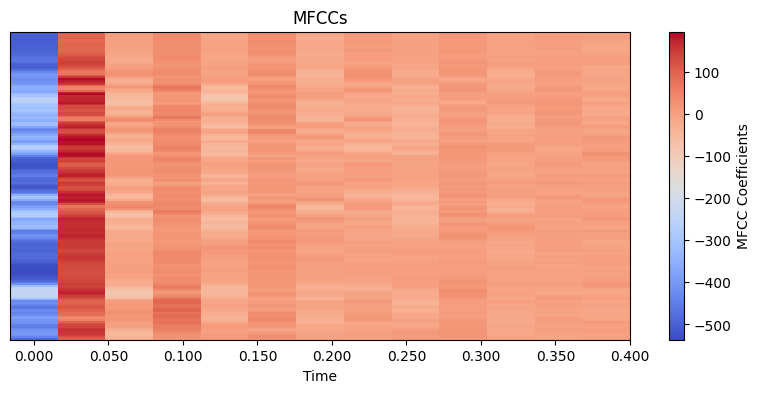

In [ ]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import librosa
import numpy as np
import torch

def extract_features(waveform, sample_rate, n_mfcc=13):
    # MFCCs
    mfccs = librosa.feature.mfcc(y=waveform.numpy(), sr=sample_rate, n_mfcc=n_mfcc)

    # Pitch (Fréquence fondamentale)
    pitches, magnitudes = librosa.piptrack(y=waveform.numpy(), sr=sample_rate)
    pitch = np.mean(pitches[pitches > 0]) if np.any(pitches > 0) else 0  # Moyenne des valeurs positives

    # Énergie
    energy = np.sum(waveform.numpy()**2) / len(waveform)

    return mfccs, pitch, energy

# Exemple d'utilisation
mfccs, pitch, energy = extract_features(waveform,sample_rate)
print(f"Pitch: {pitch}, Energy: {energy}")

# Affichage des MFCCs
plt.figure(figsize=(10, 4))
mfccs = np.squeeze(mfccs)
librosa.display.specshow(mfccs.T, sr=sample_rate, x_axis="time")
plt.colorbar(label="MFCC Coefficients")
plt.title("MFCCs")
plt.show()




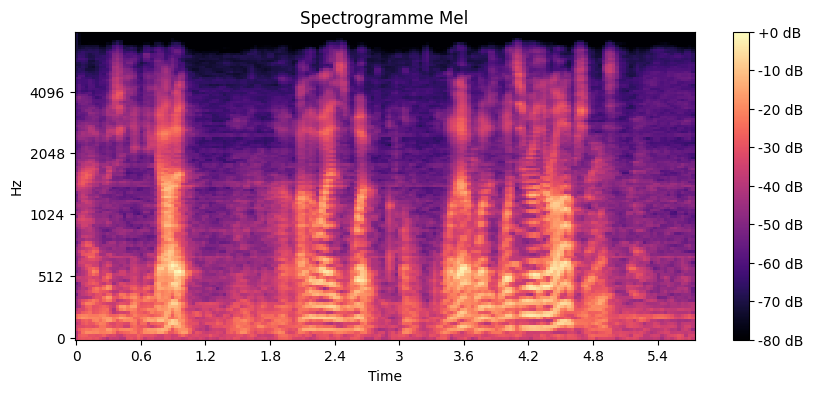

In [ ]:
import librosa.display
import matplotlib.pyplot as plt

def generate_spectrogram(waveform, sample_rate):
    S = librosa.feature.melspectrogram(y=waveform.numpy(), sr=sample_rate, n_mels=128)
    S_dB = librosa.power_to_db(S, ref=np.max)

    return S_dB

# Test sur une ligne du dataset
spectrogram = generate_spectrogram(waveform, sample_rate)
plt.figure(figsize=(10, 4))
spectrogram = np.squeeze(spectrogram)
librosa.display.specshow(spectrogram, sr=sample_rate, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title("Spectrogramme Mel")
plt.show()



In [ ]:
labels = sorted(list(set(datapoint[2] for datapoint in train_set)))
labels

['ang', 'exc', 'fru', 'hap', 'neu', 'sad']

In [ ]:
def label_to_index(word):
    return torch.tensor(labels.index(word))

def index_to_label(index):
    return labels[index]

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
import torch
import torch.nn.functional as F
import torch.nn.utils.rnn as rnn

import torch
import torch.nn.utils.rnn as rnn
from torch.nn.utils.rnn import pad_sequence

import torch
import torch.nn.functional as F
import torch.nn.utils.rnn as rnn

def preprocess_data(train_set):
    X, y = [], []

    for row in train_set:
        waveform, sample_rate, label, speaker_id, utterance_number = row
        # Extraire uniquement les MFCCs
        mfccs, pitch, energy = extract_features(waveform, sample_rate)
        mfccs = torch.tensor(mfccs, dtype=torch.float32)
        X.append(mfccs)  # Ajouter seulement les MFCCs
        y.append(label_to_index(label))

    # Trouver la taille maximale parmi toutes les séquences dans X (la longueur de la séquence, i.e., dimension 2)
    max_length = 500
    print(f"Maximum sequence length: {max_length}")

    # Appliquer du padding ou couper les séquences pour qu'elles aient la même longueur
    processed_sequences = []
    for seq in X:
        pad_size = max_length - seq.shape[2] # Calculer la taille du padding nécessaire
        if pad_size > 0:
            # Padding avec des zéros sur la dimension 3 (longueur des séquences)
            padding = torch.zeros((seq.shape[0], seq.shape[1], pad_size), dtype=torch.float32)  # Padding avec des zéros
            seq_padded = torch.cat((seq, padding), dim=2)  # Ajouter du padding sur la dimension 2
        else:
            # Couper la séquence si elle est plus longue que la taille maximale
            seq_padded = seq[:, :, :max_length]
        processed_sequences.append(seq_padded)

    # Convertir en tensor
    X = torch.stack(processed_sequences)
    y = torch.tensor(y, dtype=torch.long)

    return X, y

with open("/content/gdrive/MyDrive/ProjetST7/train_set_withoutxxx_2.pkl", "rb") as f:
  X_train = pickle.load(f)
y_train = torch.tensor([label_to_index(row[2]) for row in train_set], dtype=torch.long)


#X_train, y_train = preprocess_data(train_set)
print(f"Shape X_train: {X_train.shape}, Shape y_train: {y_train.shape}")
with open("/content/gdrive/MyDrive/ProjetST7/train_set_withoutxxx_2.pkl", "wb") as f:
  pickle.dump(X_train, f)



Shape X_train: torch.Size([5120, 1, 13, 500]), Shape y_train: torch.Size([5120])


In [ ]:
from torch.utils.data import DataLoader, TensorDataset

dataset = TensorDataset(X_train, y_train)
batch_size = 256
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

import torch
import torch.nn as nn
import torch.nn.functional as F

import torch
import torch.nn as nn

class EmotionClassificationCNN(nn.Module):
    def __init__(self):
        super(EmotionClassificationCNN, self).__init__()

        # Première couche convolutive : 1 canal d'entrée (MFCC), 16 cartes de caractéristiques de sortie
        self.conv1 = nn.Conv2d(1, 16, kernel_size=(3, 3), stride=1, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=(2, 2), stride=2, padding=0)

        # Deuxième couche convolutive : 16 cartes de caractéristiques d'entrée, 32 cartes de sortie
        self.conv2 = nn.Conv2d(16, 32, kernel_size=(3, 3), stride=1, padding=1)

        # Troisième couche convolutive : 32 cartes de caractéristiques d'entrée, 64 cartes de sortie
        self.conv3 = nn.Conv2d(32, 64, kernel_size=(3, 3), stride=1, padding=1)

        # Ajouter des couches Dropout pour éviter le surentraînement
        self.dropout1 = nn.Dropout(p=0.3)  # 30% des neurones seront désactivés

        # Couche entièrement connectée (FC) pour la classification
        # Adapter la taille d'entrée après le passage dans les couches convolutives et de pooling
        self.fc1 = nn.Linear(64 * 1 * 62, 128)  # Taille d'entrée ajustée (64 * 1 * 62)
        self.dropout2 = nn.Dropout(p=0.5)  # Dropout après la couche fc1 (50% de probabilité de désactivation)

        self.fc2 = nn.Linear(128, 6)  # Nombre de classes (par exemple, 6 émotions différentes)

    def forward(self, x):
        # Passer à travers les couches convolutives et de pooling
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))

        batch_size = x.shape[0]  # Taille dynamique du batch
        x = x.view(batch_size, -1)  # Flatten automatique

        # Appliquer le Dropout après la première couche entièrement connectée
        x = torch.relu(self.fc1(x))
        x = self.dropout2(x)  # Appliquer Dropout ici

        # Sortie finale (sans Dropout après la dernière couche)
        x = self.fc2(x)
        return x



# Initialiser le modèle
model = EmotionClassificationCNN()
model.load_state_dict(torch.load(weight_save_path, weights_only=True))

# Définir la fonction de perte et l'optimiseur
criterion = nn.CrossEntropyLoss()  # Pour la classification multi-classes
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=0.01)

num_epochs = 5
for epoch in range(num_epochs):
    model.train()  # Mettre le modèle en mode entraînement
    for batch_inputs, batch_labels in dataloader:
        optimizer.zero_grad()
        outputs = model(batch_inputs)
        loss = criterion(outputs, batch_labels)
        loss.backward()
        optimizer.step()

    print(f"Époque [{epoch + 1}/{num_epochs}], Perte: {loss.item():.4f}")

torch.save(model.state_dict(), weight_save_path)
torch.save(model, model_save_path)
print(f"Modèle enregistré sous {model_save_path}")

Époque [1/5], Perte: 1.1869
Époque [2/5], Perte: 0.9987
Époque [3/5], Perte: 1.0442
Époque [4/5], Perte: 0.9878
Époque [5/5], Perte: 1.0036
Modèle enregistré sous /content/gdrive/MyDrive/ProjetST7/emotion_classification_model_2.pth


In [ ]:
X_test, y_test = preprocess_data(test_set)


Maximum sequence length: 500


Nombre de prédictions : 5120
512 512


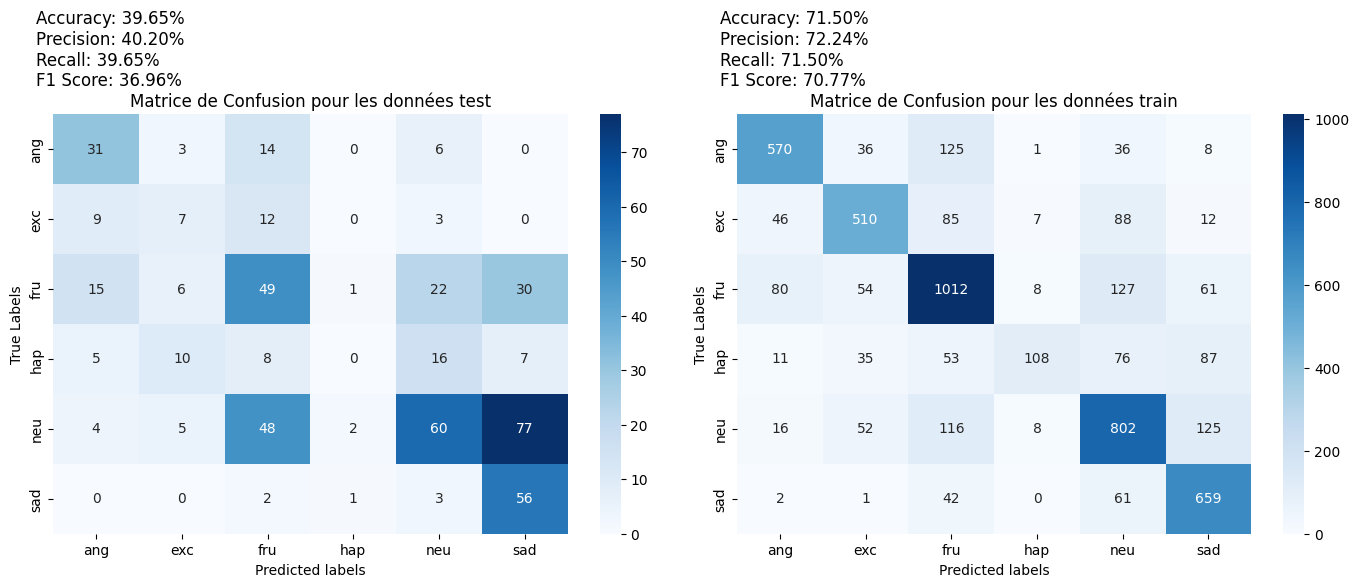

In [ ]:
model.eval()
labels = sorted(list(set(datapoint[2] for datapoint in test_set)))



result_train = []
true_labels_train = []
# Parcourir tous les batches dans le DataLoader
for batch_inputs, batch_labels in dataloader:
    output = model(batch_inputs)
    result_train.append(output)
    true_labels_train.append(batch_labels)

true_labels_train = torch.cat(true_labels_train, dim=0)
result_train = torch.cat(result_train, dim=0)
y_pred_train = torch.argmax(result_train, dim=1)

# Vérification de la taille des prédictions
print(f"Nombre de prédictions : {y_pred_train.size(0)}")


y_pred_train = torch.argmax(result_train, dim=1)
y_pred_train_index = y_pred_train
y_pred_train = [labels[i] for i in  y_pred_train]


true_labels_train_index = true_labels_train
true_labels_train = [labels[i] for i in true_labels_train]




result_test = model(X_test)
y_pred = torch.argmax(result_test, dim=1)
y_pred_index = y_pred
y_pred = [labels[i] for i in  y_pred]

true_labels_index = y_test
true_labels =[labels[i] for i in y_test]

print(len(true_labels), len(y_pred))





cm = confusion_matrix(true_labels, y_pred)
cm_train = confusion_matrix(true_labels_train, y_pred_train)

# Calcul des métriques pour les données de test
accuracy_test = accuracy_score(true_labels, y_pred) * 100
precision_test = precision_score(true_labels, y_pred, average='weighted') * 100  # 'weighted' pour traiter les déséquilibres de classes
recall_test = recall_score(true_labels, y_pred, average='weighted') * 100
f1_test = f1_score(true_labels, y_pred, average='weighted') * 100

# Calcul des métriques pour les données d'entraînement
accuracy_train = accuracy_score(true_labels_train, y_pred_train) * 100
precision_train = precision_score(true_labels_train, y_pred_train, average='weighted') * 100
recall_train = recall_score(true_labels_train, y_pred_train, average='weighted') * 100
f1_train = f1_score(true_labels_train, y_pred_train, average='weighted') * 100

# Affichage des matrices de confusion côte à côte
plt.figure(figsize=(14, 6))  # Définir la taille de la figure avec plus d'espace

# Matrice de confusion pour les données de test
plt.subplot(1, 2, 1)  # 1 ligne, 2 colonnes, premier graphique
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted labels")
plt.ylabel("True Labels")
plt.title("Matrice de Confusion pour les données test")

# Affichage des métriques pour les données de test en bas à gauche avec plus d'espace
plt.text(-0.2, -0.35, f'Accuracy: {accuracy_test:.2f}%\nPrecision: {precision_test:.2f}%\nRecall: {recall_test:.2f}%\nF1 Score: {f1_test:.2f}%',
         ha='left', va='bottom', fontsize=12, bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=1'))

# Matrice de confusion pour les données d'entraînement
plt.subplot(1, 2, 2)  # 1 ligne, 2 colonnes, deuxième graphique
sns.heatmap(cm_train, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted labels")
plt.ylabel("True Labels")
plt.title("Matrice de Confusion pour les données train")

# Affichage des métriques pour les données d'entraînement en bas à gauche avec plus d'espace
plt.text(-0.2, -0.35, f'Accuracy: {accuracy_train:.2f}%\nPrecision: {precision_train:.2f}%\nRecall: {recall_train:.2f}%\nF1 Score: {f1_train:.2f}%',
         ha='left', va='bottom', fontsize=12, bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=1'))

# Ajuster l'espacement entre les sous-graphiques
plt.subplots_adjust(wspace=0.4, hspace=0.4)  # Ajouter de l'espace entre les matrices et les métriques

# Affichage
plt.tight_layout()  # Ajuste automatiquement l'espacement pour que tout soit bien affiché
plt.show()


In [ ]:
labels_train = [i[2] for i in train_set]
labels_test = [i[2] for i in test_set]

counts = Counter(labels_train)
plt.subplot(1, 3, 1)

plt.pie(counts.values(), labels=counts.keys(), autopct='%1.1f%%', startangle=140, colors=plt.cm.Paired.colors)
plt.title("Labels des données d'entraînement")

counts = Counter(labels_test)
plt.subplot(1, 3, 3)
plt.pie(counts.values(), labels=counts.keys(), autopct='%1.1f%%', startangle=140, colors=plt.cm.Paired.colors)
plt.title("Labels des données de test")
plt.show()

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Matrices de confusion pour test et train
cm = confusion_matrix(true_labels, y_pred)  # Matrice de confusion pour les données de test
cm_train = confusion_matrix(true_labels_train, y_pred_train)  # Matrice de confusion pour les données d'entraînement

# Calcul des métriques pour les données de test
accuracy_test = accuracy_score(true_labels, y_pred)
precision_test = precision_score(true_labels, y_pred, average='weighted')  # 'weighted' pour traiter les déséquilibres de classes
recall_test = recall_score(true_labels, y_pred, average='weighted')
f1_test = f1_score(true_labels, y_pred, average='weighted')

# Calcul des métriques pour les données d'entraînement
accuracy_train = accuracy_score(true_labels_train, y_pred_train)
precision_train = precision_score(true_labels_train, y_pred_train, average='weighted')
recall_train = recall_score(true_labels_train, y_pred_train, average='weighted')
f1_train = f1_score(true_labels_train, y_pred_train, average='weighted')

# Affichage des matrices de confusion et des graphiques en camembert
plt.figure(figsize=(18, 12))  # Ajuster la taille de la figure pour plus de largeur

# Matrice de confusion pour les données de test
plt.subplot(2, 3, 1)  # 2 lignes, 3 colonnes, premier graphique
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted labels")
plt.ylabel("True Labels")
plt.title("Matrice de Confusion pour les données test")

# Affichage des métriques pour les données de test en bas à gauche avec un espacement plus important
plt.text(-0.3, -0.45, f'Accuracy: {accuracy_test:.4f}\nPrecision: {precision_test:.4f}\nRecall: {recall_test:.4f}\nF1 Score: {f1_test:.4f}',
         ha='left', va='bottom', fontsize=12, bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=1'))

# Camembert des labels pour les données de test
counts_test = Counter(labels_test)
plt.subplot(2, 3, 2)  # 2 lignes, 3 colonnes, deuxième graphique
plt.pie(counts_test.values(), labels=counts_test.keys(), autopct='%1.1f%%', startangle=140, colors=plt.cm.Paired.colors)
plt.title("Labels des données de test")

# Matrice de confusion pour les données d'entraînement
plt.subplot(2, 3, 4)  # 2 lignes, 3 colonnes, quatrième graphique
sns.heatmap(cm_train, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted labels")
plt.ylabel("True Labels")
plt.title("Matrice de Confusion pour les données train")

# Affichage des métriques pour les données d'entraînement en bas à gauche avec un espacement plus important
plt.text(-0.3, -0.45, f'Accuracy: {accuracy_train:.4f}\nPrecision: {precision_train:.4f}\nRecall: {recall_train:.4f}\nF1 Score: {f1_train:.4f}',
         ha='left', va='bottom', fontsize=12, bbox=dict(facecolor='white', alpha=0.8, edgecolor='none', boxstyle='round,pad=1'))

# Camembert des labels pour les données d'entraînement
counts_train = Counter(labels_train)
plt.subplot(2, 3, 5)  # 2 lignes, 3 colonnes, cinquième graphique
plt.pie(counts_train.values(), labels=counts_train.keys(), autopct='%1.1f%%', startangle=140, colors=plt.cm.Paired.colors)
plt.title("Labels des données d'entraînement")

# Ajuster l'espacement entre les sous-graphiques pour plus de séparation
plt.subplots_adjust(wspace=0.5, hspace=0.5)  # Ajouter plus d'espace entre les matrices et les graphiques

# Affichage
plt.tight_layout()  # Ajuste automatiquement l'espacement pour que tout soit bien affiché
plt.show()


NameError: name 'true_labels' is not defined